# v0.3 补充实验：能隙、键长敏感性与闭合能量

2026-10-18 · 对用户提供的 v0.2 的审查与独立补充。**本文件是补充笔记，不替换原文件。**

**v0.3.2（2026-10-18）：第 5 节的两件事都已完成，结论见第 6、7 节。**

- **化学验证（B3LYP/def2-SVP）：** 判据 1 通过，判据 2 不通过，按事先锁定的分档，结论为"只写机制，不写反转"。模型挑出的键长方向在真实分子中压低能隙的效率是随机对照中位数的 5.5 倍（联苯撑）和 6.6 倍（角型 [3]）；但在小形变区，角型 [3] 的双自由基特征反而更强，也是它先出现自旋对称破缺。
- **文献核对：** 加权 ASC 的零点条件、regularity radius 用于化学图、"局域 vs 集体闭合"均未找到先例；$g_0^2/P$ 机制本质上是赝 Jahn–Teller / Heilbronner 键极化率框架的推论，必须以 Fowler & Rassat（PCCP 2002）为最近先例来写。

**v0.3.1 修订（同日，直接在本文件上补充）：**

1. 去掉 Hessian，只用弛豫后前线轨道在键上的集中度 P，秩相关仍有 0.967。机制可以压缩为 $g_0^2/P$（第 1b 节）。
2. 逐对列出每个预测量排错的分子：0.983 与 0.95 之差只是一对分子的顺序，不作为谁更好的证据（第 1b 节）。
3. 枚举角型 [3] 的全部最优闭合见证：只有两个镜像解，各自局域在一端（第 1c 节）。
4. 修正第 2 节第 3 条的势垒论证；补上振动耦合 / 赝 Jahn–Teller 这条最高优先级的文献风险；写下事先登记的化学验证方案（第 5 节）。

**结果：** 在原来的 SSH 型模型、K=43 eV/Å² 下，一个不拟合参数的局部二阶近似对 9 个闭合能量的 Spearman 秩相关为 **0.9833**。只用弛豫后 gap 为 **0.7167**；原 v0.2 报告 ρ 为约 **0.95**（按精确并列处理为 0.941，见第 1b 节）。这几个数只差一两对分子的顺序，不作为排名证据。这里的非线性闭合目标值也重新优化获得，吻合原表。

这说明现有模型里的排序反转可以由“能隙如何响应键长变化，以及这种变化有多贵”解释。它是必须加入的物理基线，不是凭这 9 个点建立了新预测方法。没有重新调整 t₀、α 或 K。

## 1. 推导与化学解释

以弛豫构型为原点，记额外键长变化为 x，当前 gap 为 g₀，a=∇g 为 gap 对每条键长的敏感度，F=∇²E 为总能量的 Hessian（弯曲程度/弹性代价矩阵）。若 F 正定且最小奇异值非简并：

$$g(x)\approx g_0+a^Tx,\qquad E(x)-E_0\approx\tfrac12 x^TFx.$$

在此近似内求最便宜的零 gap 构型，拉格朗日乘子法给出

$$x_*=-\frac{g_0F^{-1}a}{a^TF^{-1}a},\qquad E_{\rm lin/harm}=\frac{g_0^2}{2a^TF^{-1}a}.$$

分母同时包含**改变 gap 的效率**与**改变这些键的代价**。若 F 的特征向量为 vₖ、特征值为 κₖ，则

$$a^TF^{-1}a=\sum_k\frac{(a^Tv_k)^2}{\kappa_k}.$$

因此可以指出哪一种协同键长变化最有效，而不只给每个分子一个分数。公式是经典约束二次优化的直接应用，不主张为新定理。

**三臂 [4] 的特殊处理：** 弛豫态最小奇异值二重简并，不能任取一根奇异向量当作唯一 gap 梯度。对其二维子空间中的单位向量 v，构造 a(v)，最大化 a(v)ᵀF⁻¹a(v)。这里只需一维角度扫描和局部细化。下方代码也核对该方向上的 gap 单侧差分。

**适用范围：** 这是局部线性 gap、二次能量模型的预测，不是非线性真实闭合能量的严格上界或下界。角型、螺旋、锯齿和三臂的绝对误差较大，不能只展示排序。


In [1]:
import numpy as np
from scipy.optimize import minimize, minimize_scalar
from scipy.stats import spearmanr

def hexagon():
    ang = np.pi/2 - np.arange(6)*np.pi/3
    return dict(n=6, edges=[(i,(i+1)%6) for i in range(6)],
                pos=[(np.cos(a), np.sin(a)) for a in ang], rings=[list(range(6))])

def fuse_polygon(g, u, v, k):
    """Fuse a regular k-gon onto bond (u,v), on the side away from the ring that already holds it."""
    pos = np.array(g['pos'], float)
    host = next(r for r in g['rings'] if u in r and v in r)
    pu, pv = pos[u], pos[v]; mid, d = (pu+pv)/2, pv-pu
    nrm = np.array([-d[1], d[0]]); nrm /= np.linalg.norm(nrm)
    if np.dot(nrm, mid-pos[host].mean(0)) < 0: nrm = -nrm
    L = np.linalg.norm(d); c = mid + L/(2*np.tan(np.pi/k))*nrm; R = L/(2*np.sin(np.pi/k))
    a_u = np.arctan2(*(pu-c)[::-1]); a_v = np.arctan2(*(pv-c)[::-1]); step = 2*np.pi/k
    wrap = lambda x: (x+np.pi) % (2*np.pi) - np.pi
    sgn = 1 if abs(wrap(a_u + step*(k-1) - a_v)) < 1e-6 else -1
    new = list(range(g['n'], g['n']+k-2))
    newpos = [tuple(c + R*np.array([np.cos(a_u+sgn*step*(i+1)), np.sin(a_u+sgn*step*(i+1))])) for i in range(k-2)]
    path = [u]+new+[v]
    return dict(n=g['n']+k-2, edges=g['edges']+list(zip(path[:-1], path[1:])),
                pos=list(g['pos'])+newpos, rings=g['rings']+[path]), path

def phenylene(choices):
    """[N]phenylene, N = len(choices)+2. For each internal benzene: 'p' = para (linear),
    'L'/'R' = angular to either side. With this construction ['L','L'] is zigzag, ['L','R'] helical."""
    g = hexagon(); a, b = 2, 3
    for step in range(len(choices)+1):
        g, sq = fuse_polygon(g, a, b, 4)
        g, hx = fuse_polygon(g, sq[2], sq[1], 6)
        if step < len(choices):
            a, b = {'p': (hx[2], hx[3]), 'L': (hx[1], hx[2]), 'R': (hx[3], hx[4])}[choices[step]]
    return g

def triangular4():
    g = hexagon()
    for a, b in [(0,1),(2,3),(4,5)]:
        g, sq = fuse_polygon(g, a, b, 4); g, _ = fuse_polygon(g, sq[2], sq[1], 6)
    return g

def benzocyclobutadiene_g():
    g = hexagon(); g, _ = fuse_polygon(g, 2, 3, 4); return g

def naphthalene_g():
    g = hexagon(); g, _ = fuse_polygon(g, 2, 3, 6); return g

def check_geometry(g):
    P = np.array(g['pos'])
    assert all(abs(np.linalg.norm(P[u]-P[v])-1) < 1e-6 for u, v in g['edges'])
    D = np.linalg.norm(P[:,None]-P[None], axis=-1) + 10*np.eye(g['n'])
    assert D.min() > 0.5, 'overlapping atoms'
    assert np.bincount(np.array(g['edges']).ravel()).max() <= 3

def bipartite(g):
    """Return T (rows = one sublattice, cols = the other) and, for every bond in g['edges'], its (i,j) in T."""
    n, E = g['n'], g['edges']; adj = [[] for _ in range(n)]
    for u, v in E: adj[u].append(v); adj[v].append(u)
    col, q = {0: 0}, [0]
    for u in q:
        for v in adj[u]:
            if v not in col: col[v] = 1-col[u]; q.append(v)
            assert col[v] != col[u], 'not bipartite'
    L = [i for i in range(n) if col[i] == 0]; R = [i for i in range(n) if col[i] == 1]
    assert len(L) == len(R)
    li = {a: i for i, a in enumerate(L)}; ri = {a: j for j, a in enumerate(R)}
    T = np.zeros((len(L), len(R))); bix = []
    for u, v in E:
        i, j = (li[u], ri[v]) if u in li else (li[v], ri[u])
        T[i, j] = 1; bix.append((i, j))
    return T, L, R, bix


class BondModel:
    """Hückel pi + harmonic sigma springs.  t_b = t0 - alpha*delta_b ;
    E = -2 * sum(singular values of the weighted T) + sum_b (K/2 delta_b^2 + c delta_b),
    with c = -2*alpha*p_ref so that benzene (bond order 2/3) is stationary at delta = 0.
    At equilibrium delta_b = 2*alpha*(p_ref - p_b)/K: a Coulson-type bond-order/bond-length line
    with slope 2*alpha/K (0.19 A per unit bond order for K = 43). Units: eV, angstrom."""
    def __init__(self, g, t0=2.5, alpha=4.1, K=43.0, p_ref=2/3):
        self.T0, self.L, self.R, self.bix = bipartite(g)
        self.t0, self.a, self.K, self.c = t0, alpha, K, -2*alpha*p_ref
        self.ii = np.array([i for i, j in self.bix]); self.jj = np.array([j for i, j in self.bix]); self.m = len(self.bix)
    def Tw(self, d):
        T = np.zeros_like(self.T0); T[self.ii, self.jj] = self.t0 - self.a*d; return T
    def energy(self, d):
        U, s, Vt = np.linalg.svd(self.Tw(d)); p = (U @ Vt)[self.ii, self.jj]
        return -2*s.sum() + np.sum(0.5*self.K*d**2 + self.c*d), 2*self.a*p + self.K*d + self.c
    def gap(self, d): return 2*np.linalg.svd(self.Tw(d), compute_uv=False)[-1]
    def det(self, d):
        U, s, Vt = np.linalg.svd(self.Tw(d)/self.t0); sg = np.linalg.det(U)*np.linalg.det(Vt)
        cof = np.array([np.prod(np.delete(s, k)) for k in range(len(s))])
        adjT = sg*(U*cof) @ Vt
        return sg*np.prod(s), adjT[self.ii, self.jj]*(-self.a/self.t0)
    def relax(self):
        r = minimize(self.energy, np.zeros(self.m), jac=True, method='BFGS', options=dict(gtol=1e-9, maxiter=5000))
        return r.x, r.fun
    def closure(self, starts):
        """Lowest-energy geometry found with det(T) = 0, i.e. Hückel gap exactly zero (multi-start SLSQP)."""
        best = None; bnd = [(-0.8*self.t0/self.a, 0.8*self.t0/self.a)]*self.m
        for d0 in starts:
            r = minimize(self.energy, d0, jac=True, method='SLSQP', bounds=bnd,
                         constraints=[dict(type='eq', fun=lambda d: self.det(d)[0], jac=lambda d: self.det(d)[1])],
                         options=dict(ftol=1e-12, maxiter=1000))
            if r.success and abs(self.det(r.x)[0]) < 1e-8 and (best is None or r.fun < best.fun): best = r
        return best


mols = {
 'benzene': (hexagon(), 'reference'), 'naphthalene': (naphthalene_g(), 'reference'),
 'benzocyclobutadiene': (benzocyclobutadiene_g(), 'reference'),
 'biphenylene': (phenylene([]), 'linear'),
 'linear[3]': (phenylene(['p']), 'linear'), 'angular[3]': (phenylene(['L']), 'angular/branched'),
 'linear[4]': (phenylene(['p','p']), 'linear'), 'bent[4]': (phenylene(['p','L']), 'angular/branched'),
 'helical[4]': (phenylene(['L','R']), 'angular/branched'), 'zigzag[4]': (phenylene(['L','L']), 'angular/branched'),
 'triangular[4]': (triangular4(), 'angular/branched')}


In [2]:
# Targets transcribed from the supplied notebook output, K=43 eV/A^2.
target={'benzocyclobutadiene':2.0130019221865,'biphenylene':4.179929259151898,'linear[3]':2.695871849206,'angular[3]':4.77135017238863,'linear[4]':1.87,'bent[4]':3.05,'helical[4]':4.51,'zigzag[4]':4.52,'triangular[4]':5.55}
rows=[]
for name in target:
 bm=BondModel(mols[name][0],K=43.);d,E=bm.relax();U,s,Vt=np.linalg.svd(bm.Tw(d));g=2*s[-1]
 h=1e-5;eye=np.eye(bm.m)
 Hess=np.column_stack([(bm.energy(d+h*eye[k])[1]-bm.energy(d-h*eye[k])[1])/(2*h) for k in range(bm.m)])
 Hess=(Hess+Hess.T)/2
 lam=np.linalg.eigvalsh(Hess);assert lam[0]>0
 deg=int(np.sum(abs(s-s[-1])<1e-7))
 def agrad_vec(v):
  left=U[:,-deg:]@v;right=Vt[-deg:,:].T@v
  return -2*bm.a*left[bm.ii]*right[bm.jj]
 if deg==1:
  a=agrad_vec(np.ones(1))
 else:
  assert deg==2
  Hi=np.linalg.inv(Hess)
  def negcomp(theta):
   aa=agrad_vec(np.array([np.cos(theta),np.sin(theta)]));return -(aa@Hi@aa)
  grid=np.linspace(0,np.pi,2048,endpoint=False);best=int(np.argmin([negcomp(t) for t in grid]));delta=np.pi/2048
  rr=minimize_scalar(negcomp,bounds=(grid[best]-delta,grid[best]+delta),method='bounded',options={'xatol':1e-13})
  a=agrad_vec(np.array([np.cos(rr.x),np.sin(rr.x)]))
 compliance=a@np.linalg.solve(Hess,a)
 pred=g*g/(2*compliance)
 pred_sigma=43*g*g/(2*(a@a))
 # independent numerical gradient of gap verifies frontier derivative.
 if deg==1:
  agrad=np.array([(bm.gap(d+h*v)-bm.gap(d-h*v))/(2*h) for v in eye])
  assert max(abs(a-agrad))<1e-6
 else:
  direction=-np.linalg.solve(Hess,a)
  fd=(bm.gap(d+1e-4*direction)-bm.gap(d))/1e-4
  assert abs(fd-a@direction)<1e-4
 proposal=-g*np.linalg.solve(Hess,a)/compliance
 sol=bm.closure([d+f*proposal for f in [.7,1,1.3]])
 rows.append((name,g,pred,pred_sigma,sol.fun-E,lam[0],compliance))
 print(name,'gap',round(g,6),'harmonic estimate',round(pred,6),'target',target[name],'new_closure',sol.fun-E if sol else None,'Hessian min eig',round(lam[0],6),'degeneracy',deg,flush=True)
print('Spearman full Hessian:',spearmanr([r[2] for r in rows],[r[4] for r in rows]).statistic)

print('Spearman relaxed gap:',spearmanr([r[1] for r in rows],[r[4] for r in rows]).statistic)


benzocyclobutadiene gap 2.089268 harmonic estimate 2.002458 target 2.0130019221865 new_closure 2.0130019221866284 Hessian min eig 28.445389 degeneracy 1


biphenylene gap 2.582166 harmonic estimate 4.313271 target 4.179929259151898 new_closure 4.179929259152047 Hessian min eig 28.695203 degeneracy 1


linear[3] gap 1.748198 harmonic estimate 2.674688 target 2.695871849206 new_closure 2.695871849205247 Hessian min eig 28.222474 degeneracy 1


angular[3] gap 2.390578 harmonic estimate 5.628745 target 4.77135017238863 new_closure 4.771350172388701 Hessian min eig 28.280944 degeneracy 1


linear[4] gap 1.347899 harmonic estimate 1.925961 target 1.87 new_closure 1.866518654987658 Hessian min eig 27.946024 degeneracy 1


bent[4] gap 1.772242 harmonic estimate 3.111844 target 3.05 new_closure 3.0466708382942045 Hessian min eig 28.03826 degeneracy 1


helical[4] gap 2.081439 harmonic estimate 5.492091 target 4.51 new_closure 4.5125898712811505 Hessian min eig 28.111217 degeneracy 1


zigzag[4] gap 2.202796 harmonic estimate 5.934897 target 4.52 new_closure 4.518183830265883 Hessian min eig 28.084063 degeneracy 1


triangular[4] gap 2.483808 harmonic estimate 7.479821 target 5.55 new_closure 5.547309674955656 Hessian min eig 28.330679 degeneracy 2


Spearman full Hessian: 0.9833333333333333
Spearman relaxed gap: 0.7166666666666667


## 1b. 去掉 Hessian：前线轨道在键上的集中度

上面的梯度来自 `agrad_vec`：$a_b=-2\alpha\,u_iv_j$，其中 u、v 是最小奇异值对应的左右奇异向量（前线轨道在两个子晶格上的系数），键 b 连接 i 和 j。因此

$$a^Ta=4\alpha^2P,\qquad P=\sum_b (u_iv_j)^2 .$$

P 衡量前线轨道的跃迁密度有多集中在少数几条键上。如果 Hessian 近似为常数乘单位矩阵 $F\approx\kappa I$，闭合能量估计就变成

$$\Delta E\approx\frac{\kappa}{8\alpha^2}\,\frac{g_0^2}{P}.$$

第 1 节代码中已有的 `pred_sigma` 一列正是这个量（取 κ = K），只是没有报告。下面检查 Hessian 的本征值是否真的接近常数，以及只用 $g_0^2/P$ 时排序还剩多少；同时逐对列出各预测量排错的分子，ρ 取 v0.2 精确计算的结果。


In [3]:
# rho: exact Rohn values from v0.2 (section 6 output), K-independent
rho_v02 = {'benzocyclobutadiene':0.119725922957,'biphenylene':0.188828952032,'linear[3]':0.119725922957,
           'angular[3]':0.196160558133,'linear[4]':0.075580833701,'bent[4]':0.126471619937,
           'helical[4]':0.161395486329,'zigzag[4]':0.161395486329,'triangular[4]':0.203142021055}
dE_nl = {r[0]: r[4] for r in rows}            # nonlinear closure energies recomputed in section 1
E_hess = {r[0]: r[2] for r in rows}
info = {}
for name in target:
    bm = BondModel(mols[name][0], K=43.); d, E = bm.relax(); U, s, Vt = np.linalg.svd(bm.Tw(d)); g = 2*s[-1]
    h = 1e-5; eye = np.eye(bm.m)
    F = np.column_stack([(bm.energy(d+h*eye[k])[1]-bm.energy(d-h*eye[k])[1])/(2*h) for k in range(bm.m)])
    lam = np.linalg.eigvalsh((F+F.T)/2)
    deg = int(np.sum(abs(s-s[-1]) < 1e-7))
    thetas = [0.0] if deg == 1 else np.linspace(0, np.pi, 721)
    def P_of(th):
        v = np.ones(1) if deg == 1 else np.array([np.cos(th), np.sin(th)])
        l = U[:, -deg:] @ v; r = Vt[-deg:].T @ v
        return np.sum((l[bm.ii]*r[bm.jj])**2)
    P = max(P_of(t) for t in thetas)          # degenerate case: most concentrated combination
    info[name] = dict(g=g, P=P, lam_min=lam.min(), lam_max=lam.max())

names = list(target)
print(f'{"molecule":20s}{"g0/eV":>8s}{"P":>8s}{"g0^2/P":>9s}{"E_hess":>8s}{"dE":>8s}{"Hessian eig range":>20s}')
for n in names:
    i = info[n]
    print(f'{n:20s}{i["g"]:8.3f}{i["P"]:8.4f}{i["g"]**2/i["P"]:9.3f}{E_hess[n]:8.3f}{dE_nl[n]:8.3f}{i["lam_min"]:12.1f} - {i["lam_max"]:.1f}')

preds = {'Hessian estimate': E_hess, 'g0^2/P (no Hessian)': {n: info[n]['g']**2/info[n]['P'] for n in names},
         'rho (v0.2)': rho_v02, 'relaxed gap g0': {n: info[n]['g'] for n in names}, '1/P alone': {n: 1/info[n]['P'] for n in names}}
y = [dE_nl[n] for n in names]
print('\nSpearman with the nonlinear closure energy, and the pairs each predictor gets wrong or ties:')
for lab, p in preds.items():
    x = [p[n] for n in names]
    wrong = [(a, b) for k, a in enumerate(names) for b in names[k+1:]
             if (p[a]-p[b])*(dE_nl[a]-dE_nl[b]) < 0]
    ties = [(a, b) for k, a in enumerate(names) for b in names[k+1:] if abs(p[a]-p[b]) < 1e-9]
    print(f'  {lab:22s} {spearmanr(x, y).statistic:6.3f}   wrong: {wrong if wrong else "none"}' + (f'   ties: {ties}' if ties else ''))


molecule               g0/eV       P   g0^2/P  E_hess      dE   Hessian eig range
benzocyclobutadiene    2.089  0.6440    6.778   2.002   2.013        28.4 - 43.0
biphenylene            2.582  0.4485   14.866   4.313   4.180        28.7 - 43.0
linear[3]              1.748  0.3263    9.365   2.675   2.696        28.2 - 43.0
angular[3]             2.391  0.2743   20.833   5.629   4.771        28.3 - 43.0
linear[4]              1.348  0.2676    6.790   1.926   1.867        27.9 - 43.0
bent[4]                1.772  0.2815   11.156   3.112   3.047        28.0 - 43.0
helical[4]             2.081  0.2123   20.402   5.492   4.513        28.1 - 43.0
zigzag[4]              2.203  0.2286   21.223   5.935   4.518        28.1 - 43.0
triangular[4]          2.484  0.2257   27.336   7.480   5.547        28.3 - 43.0

Spearman with the nonlinear closure energy, and the pairs each predictor gets wrong or ties:
  Hessian estimate        0.983   wrong: [('angular[3]', 'zigzag[4]')]
  g0^2/P (no Hessian)   

**读法。**

- Hessian 的本征值全部落在约 28–43 eV/Å² 之间，上限就是 K 本身（与 π 电子无关的方向），π 电子只把一部分方向软化到 28 左右。所以 Hessian 对排序贡献很小，$g_0^2/P$ 已经抓住了主要行为。
- **机制因此可以压缩为一句话：** 闭合代价约等于能隙平方除以前线轨道在键上的集中度。前线轨道挤在少数键上（P 大），少数几条键协同变形就能关掉能隙；轨道铺满整条链（P 小），需要很多键一起动。这与 v0.2 第 6 节"局域闭合 vs 集体闭合"的图像是同一件事。
- 反转那一对：联苯撑的 P 约 0.45，角型 [3] 约 0.27。角型 [3] 的能隙更小，但前线轨道摊得更开，所以更难关。
- 单独的 1/P 秩相关很低，**必须和 $g_0$ 一起用**。
- 这里 ρ 的秩相关是 0.941，不是 v0.2 报告的 0.950。差别来自浮点：v0.2 中螺旋型与锯齿型的 ρ 在第 16 位小数上不同，恰好排成与闭合能量一致的顺序；按真实的并列处理就是 0.941。
- 几个预测量各自只错一两对、有的还有并列。九个点上这点差别是噪声，排名本身不构成证据；有价值的是 $g_0^2/P$ 这个可以解释的分解。P 是纯 Hückel 量，在 DFT 中对应 HOMO–LUMO 跃迁密度在各条键上的分布，可以直接拿去检验。


## 1c. 角型 [3] 的闭合见证是否唯一

v0.2 的零模图每个分子只画了一个精确见证。角型 [3] 有一个交换两端的对称操作，所以最优见证可能不止一个。下面枚举全部 $(y,z)\in\{\pm1\}^9\times\{\pm1\}^9$，找出达到最大实本征值的所有符号组合，并计算每个见证下闭合轨道在各个环上的份额。


In [4]:
from itertools import product
g = mols['angular[3]'][0]; T, Lr, Rr, bix = bipartite(g); n = len(T); Ti = np.linalg.inv(T)
ys = np.array(list(product([-1, 1], repeat=n)), float)
A = np.einsum('ij,yj,jk->yik', Ti, ys, T)
lam_best, found = -np.inf, []
for z in ys:
    lam = np.linalg.eigvals(A*z[None, None, :])
    lm = np.where(abs(lam.imag) < 1e-9, lam.real, -np.inf).max(1)
    k = lm.max()
    if k > lam_best + 1e-9: lam_best, found = k, []
    if k > lam_best - 1e-9:
        found += [(ys[i].copy(), z.copy()) for i in np.nonzero(lm > lam_best - 1e-9)[0]]
rho_a = 1/lam_best
print(f'rho(angular[3]) = {rho_a:.12f}; optimal (y,z) patterns: {len(found)} (each witness appears with both global signs)')
patterns = {}
for y_, z_ in found:
    W = T - rho_a*(T*np.outer(y_, z_)); U, s, Vt = np.linalg.svd(W)
    w = np.zeros(g['n']); w[Lr] = U[:, -1]**2; w[Rr] = Vt[-1]**2
    shares = np.array([sum(w[a] for a in rg) for rg in g['rings']]); shares /= shares.sum()
    patterns[tuple(float(x) for x in np.round(shares, 2))] = s[-1]
for sh, smin in patterns.items():
    print('  ring shares (B, S, B, S, B):', sh, f'  sigma_min at witness = {smin:.1e}')


rho(angular[3]) = 0.196160558133; optimal (y,z) patterns: 4 (each witness appears with both global signs)
  ring shares (B, S, B, S, B): (0.03, 0.07, 0.29, 0.33, 0.28)   sigma_min at witness = 2.8e-16
  ring shares (B, S, B, S, B): (0.28, 0.33, 0.29, 0.07, 0.03)   sigma_min at witness = 1.2e-16


扣除整体符号后只有两个最优见证，互为镜像，各自集中在一端的苯–四元环–苯单元（约 0.9 对 0.1）。**没有离域的最优解。** 对这个分子，"闭合是局域的"成立，并且有两个等价位置。v0.2 的图注应补上"另有一个镜像等价解"。其余分子尚未做同样的枚举。


## 2. 原 v0.2 中应改正的结论

1. **Rohn 公式正确，文字判据不正确。** 对给定 ε，参数盒含奇异矩阵，并不等价于恰在该 ε 的某个特殊顶点奇异。标量例子 T=[1], ε=2：区间 [-1,3] 含零，但两个顶点都非零。正确的是首次接触奇异集合的半径可由这些特殊顶点路径的首次零点求出。Poljak–Rohn 的最大实谱半径公式仍适用。代码遍历了 y 及 −y，所以用最大全部正实本征值与最大实本征值绝对值等价。
2. **“精确算法”与“严格数值证书”分开。** 枚举是穷尽搜索，顶点定理是严格的。普通浮点 eigvals、det 与 brentq 的输出尚不是区间算术或有理算术证书。即使两端的符号严格认证，也首先得到一个包含 ρ 的区间；闭式或代数根的识别需要额外论证。
3. **局部最优闭合构型不能给出能量下限。** 若参考弛豫态已是全局最小值，找到一个可行闭合构型给出最小闭合能量的上界。原代码仅从均匀构型做一次 BFGS 弛豫，参考态也没有全局证书。因此必须称为“相对找到的弛豫态，已找到的最低闭合构型能量差”。不能据此证明热涨落不可达，也不能把端点能量差当成路径的活化势垒。

   **补充（v0.3.1）：** 端点与势垒的区别不削弱"到不了"的结论。任何到达零 gap 构型的路径，终点都落在零 gap 集合上，所以路径上的最高能量不低于该集合上的最低能量，即势垒 ≥ 最小闭合能量。真正缺的只有一点：没有证明找到的闭合构型就是集合上的最低点。多起点优化和第 1 节的局部近似是两条独立途径，结果同一量级（约 2–7 eV，远大于热能 0.026 eV）。合适的写法是"模型内找到的最低闭合能量约为多少，局部近似给出同一量级，尚未证明是全局最小；很可能不可达"。
4. **“ρ 是 gap 的马甲”证据不够。** 五个异构体没有排序反转，只能说明在这个集合中没有显示排序优势。ρ 对螺旋/锯齿并列，而 gap 不同；这既不是证明冗余，也不是证明更好。
5. **苯型烃的条件要写全。** 同号且至少有一个完美匹配，才保证正权重不奇异。无 Kekulé 结构的二分图可能本来就有零模。图中一般 4n 圈不等于可在两种完美匹配间交替的 4n 圈。
6. **零 gap 不等于一个经验证的双自由基阈值。** 模型中零 gap 是一电子简并；要接上实际双自由基性质，需要自然轨道占据、单重态–三重态能量差或相应多电子模型。忽略相关的能量误差也不能自动推导为闭合能量差偏高，因为两个构型的相关修正都要考虑。
7. **对称性不能无条件减少最坏扰动搜索。** 对称参考分子的分块只对保持该对称性的扰动继续成立；独立边权允许破坏对称性的方向。只搜对称方向通常给出全空间最小扰动的上界。
8. **零模图是特定见证的结果。** 若 T 的零空间为一维，H 有两维零空间；代码图示相当于两根子晶格零模的平均权重。还要检查多个最优见证，以及更高零空间维数，才能把一张图推广为分子的唯一“闭合位置”。

   **补充（v0.3.1）：** 第 1c 节已对角型 [3] 做了全部枚举：只有两个互为镜像的最优见证，各自局域在一端，零空间一维。局域图像对这个分子成立；其余分子待查。

## 3. 本次核验范围

- 重跑前四个可闭合骨架的 Rohn 半径，吻合 v0.2；未重跑五个 [4] 骨架的全部 Rohn 枚举。
- 前四个骨架 × K=21,43,60 的闭合能量重跑吻合；每个弛豫态额外做 12 个随机起点，未找到更低的极小值。这是数值支持，非全局证明。
- K=43 的九个骨架全部计算 Hessian，最小特征值约 28 eV/Å²，均为正；非简并情况下核对解析 gap 梯度与有限差分。
- 用局部近似给出的方向作为 SLSQP 起点，九个骨架均重现原表闭合能量。该步骤与原来用 ρ 见证起步不同，但采用同一能量函数。

## 4. 文献核验与选题判断

- **[v0.3.2 核对结果]** 已查的直接文献与结论（全文未取得者注明）：
  - [Fowler & Rassat, *Symmetry and distortive π-electrons in two- and three-dimensional conjugated systems*, PCCP 4, 1105 (2002)](https://doi.org/10.1039/B109712C)：Heilbronner 模型（固定每个顶点的键参数之和）、键极化率本征向量与"对称性降低的前线轨道规则"，并给出自发畸变阈值。体系为多烯、并苯、碳棱柱与 C60，未涉及 4n 环稠合体系。**这是第 1b 节机制最近的先例，仅读到摘要，必须读全文**，确认其前线轨道规则是否就是 P。
  - Sato 等的 vibronic coupling density：非对角 VCD 用跃迁密度乘以势能导数，P 是它在 Hückel 层次、按键分解的类比，但不完全相同。未发现用于 phenylene、反芳香体系或双自由基的工作。
  - Langler 2008（[CH07217](https://doi.org/10.1071/CH07217)）及其姊妹篇 CH07216、CH07218：据摘要只做拓扑分析（β 固定），未见键权重或键长变化。全文未取得。
  - 加权 ASC 的零点、regularity radius 用于化学图：未找到。phenylene 的未加权 ASC 有现成结果（如 Gutman 2003：线型 phenylene 的 ASC = h+1）。
  - 角型 [3]phenylene 未找到已发表的 y0；实验 S1 能量见 [Dosche 等, PCCP 4, 2156 (2002)](https://publishup.uni-potsdam.de/files/1112/Dosche_2002.pdf)：联苯撑约 24.0、角型 [3] 23.0（10³ cm⁻¹）。
  - [Moles Quintero 等, Angew. 2022](https://doi.org/10.1002/anie.202209138)：y0 是杂化能与相关能的权衡，并给出过能隙缩小而 y0 不增的例子，但没有归因于前线轨道在键上的集中度。
- **[v0.3.1 新增，最高优先]** 振动耦合与赝 Jahn–Teller 理论（Bersuker），以及 Sato 等人的 vibronic coupling density 分析：[Kato, Haruta, Sato, *Vibronic Coupling Density: Understanding Molecular Deformation*, Springer 2021](https://www.springer.com/cn/book/9789811617959)。"能隙对哪些键长变化敏感，再按力常数加权"正是这一框架的核心问题；反芳香分子靠键长交替打开能隙，是赝 Jahn–Teller 的标准例子。第 1b 节的 $g_0^2/P$ 机制本身大概率已有覆盖。可能剩下的新内容是：ASC 给出的严格闭合条件，以及"连接方式决定前线轨道在键上是局域集中还是整链分摊"这条结构规律，两者与振动耦合框架的衔接。这一项比 Langler 2008 更需要先查。

- [Hartman & Hladík, arXiv:1806.09988](https://arxiv.org/abs/1806.09988)，已读公式 (4)：广义 regularity radius 的 Poljak–Rohn 公式；这部分数学优先权明确。
- [Graovac et al., Croat. Chem. Acta 72 (1999), 853–867](https://hrcak.srce.hr/en/132304)，官方页面确认题名、作者、页码及 polygraph/phenylene ASC 算法的摘要。不能把带符号 Kekulé 展开称为新理论。
- [Dewar & Longuet-Higgins, Proc. R. Soc. A 214 (1952), 482–493](https://doi.org/10.1098/rspa.1952.0184)。DOI 得到 Royal Society 官方档案索引的交叉核对，卷页亦有后续论文参考文献支持；本轮未取得原文全文。
- [Langler, Aust. J. Chem. 61 (2008), 26–35](https://doi.org/10.1071/CH07217)。检索取得摘要和部分正文片段，出版商全文及镜像读取受阻。已知其讨论环型改变与 Hückel 稳定性；不能据现有片段断言它已经或尚未做过我们的加权最小扰动问题。

**候选主张（v0.3.1 收紧）：**

> 能隙大小不决定它有多难被关掉。决定它的是能隙与前线轨道在键上集中程度之比；连接方式决定这种集中是局域的还是整条链共享的，因此能隙更大的分子反而可能更容易被推向开壳层。

前半句在本模型内已有支持（第 1、1b 节），后半句的化学含义由第 5 节的验证决定。

**继续研究的主问题建议：** 哪些协同键长变化能最有效地缩小前线能隙，分子连接方式如何决定这些变化是局域的还是集体的？以解析闭合条件解释极限情形，以弹性加权响应解释能量代价，再用一个多电子/真实几何例子检验能否通向可控开壳层。ρ 保留为几何距离基准，不要求它在所有排序中战胜 gap。

**明确的风险：** 模型缺少角度与几何约束；局部近似对简并态和远离平衡的构型需要专门处理；具体化学命题的优先权尚未查完。已有加权零点理论本身不构成整个问题已被解决的证据。


## 5. 下一轮：只做两件事（事先登记）

**收尾规则：** 下一轮只做关键文献核对和一组带对照的化学验证。做完就决定写稿或归档，不自动开启新一轮升级。

### 5.1 关键文献核对

按顺序：振动耦合 / 赝 Jahn–Teller 与 vibronic coupling density 的直接文献及其引用链；Langler 2008 全文；ASC 加权或键长依赖的推广。判断标准：前人是否已经给出**同样的机制、同样的判据、同样的验证**。只找到相邻理论不构成换题理由；核心贡献已被覆盖才换题。读完最近的关键文献和直接引用链就下结论，不无限检索。

### 5.2 带对照的化学验证

- **分子对：** 联苯撑与角型 [3]phenylene，也就是本模型中的反转对。
- **待检验的预测：** 角型 [3] 能隙更小，但更难被推向开壳层，原因是前线轨道在键上更分散（P 更小）。
- **方向：** 预测方向 $x_*=-g_0F^{-1}a/(a^TF^{-1}a)$。对照方向取弹性代价 $\tfrac12x^TFx$ 相同的两类：全对称键长交替模式，以及一批随机方向（报告其分布）。
- **几何实现：** 用 DFT 优化真实几何。环中的键长不能独立变化，用内坐标（Wilson B 矩阵）把键长模式投影成可实现的笛卡尔位移，并报告投影后保留的比例。保留比例过低时，预测方向在真实分子中不存在，这本身就是一个结论。
- **观测量：** KS HOMO–LUMO 能隙；broken-symmetry UDFT 的 ⟨S²⟩ 与开壳层稳定化能；单重态–三重态能隙；条件允许时，用 CAS(2,2) 自然轨道占据数算双自由基指数 y₀。
- **通过判据（计算前锁定）：**
  1. 两个分子中，沿预测方向单位能量造成的能隙下降，都至少是同代价对照方向中位数的 1.5 倍；
  2. 在相同变形能量下，联苯撑比角型 [3] 更早出现开壳层特征（⟨S²⟩ 偏离零，或 y₀ 更大）。

  两条都过，写化学故事；第 1 条过、第 2 条不过，只写机制、不写反转；第 1 条不过，结论停在模型层面并归档。
- **工具与成本：** PySCF，def2-SVP，C₁₂H₈ 与 C₁₈H₁₀，两核机器数小时量级。


## 6. 化学验证：B3LYP 中预测方向是否仍然有效（第 5.2 节的执行结果）

**做了什么。** 联苯撑与角型 [3]phenylene 各自在 B3LYP/def2-SVP（密度拟合，PySCF 2.14）下优化平衡几何，然后沿模型给出的方向做**固定位移、不再弛豫**的单点计算。所有原始数据、脚本和事先登记文件都在本笔记本旁边的 `dft_validation/` 目录中；本节只读取结果文件，不重跑 DFT（全部计算在 2 核机器上约 8 小时）。

**平衡几何的合理性检查。** 联苯撑四元环的环间键 1.509 Å（实验约 1.51 Å）。角型 [3] 中心苯环的键长在 1.358–1.458 Å 之间交替，呈明显的键定域。这与 Vollhardt 等人对角型 phenylene 中心环"环己三烯化"的描述一致。B3LYP 的 HOMO–LUMO 能隙：联苯撑 4.10 eV，角型 [3] 3.75 eV，排序与 Hückel 和实验 S1 能量（Dosche 等 2002）相同。

**方向与幅度。** 方向在模型的 C–C 键长空间中定义，按模型弹性能 ½xᵀFx 归一：

- **P**：模型预测的最省能缩小能隙方向 x* ∝ −F⁻¹a；
- **C_BLA**：撤销模型平衡键长交替（让键长趋于均匀）的全对称方向；
- **C_rand**：8 个随机方向，正负两个符号都算。

键长模式通过 Wilson B 矩阵（只动碳原子，氢跟随所连碳原子平移）迭代求解为笛卡尔位移，所有构型实测键长变化与目标的余弦均为 1.0000，最大偏差小于 10⁻¹⁵ Å。**模型中的键长模式在真实几何中可以精确实现**，不存在"环约束导致投影损失"的问题；代价全部体现在 DFT 能量里。

**观测量。** RKS 能隙与形变能（全部构型）；沿 P 的阶梯和参考点上，broken-symmetry UB3LYP 的 ⟨S²⟩、单重态–三重态能隙，以及 UHF 自然轨道的双自由基指数 y0（Yamaguchi 公式，Nakano 等常用的 PUHF 型指标）。

**与事先登记的偏差（全部记录在 `PREREGISTRATION.md` 的变更记录中，SHA-256 链见下方输出）：**

1. CASSCF(2,2) 太慢（联苯撑单点约 8 分钟，角型 [3] 估计数小时），y0 改用 UHF 自然轨道计算。改动时只有联苯撑参考点的 CASSCF 结果（y0 = 0.058）。
2. 第一次 UHF 计算中，角型 [3] 参考点收敛到几乎是 RHF 的解（y0 ≈ 0），而联苯撑有强烈的对称破缺。这是收敛方式的假象，于是加入反铁磁初猜（两个碳子晶格放相反自旋），两种初猜取能量较低者，两个分子全部重算。**这一修正发生在看到部分数据之后**：当时已有联苯撑参考点和 P 阶梯 0.5–2.0 eV 的结果，以及角型 [3] 的错误参考点。修正后，角型 [3] 参考点的 UHF 能量比原来低约 1.1 eV，y0 从约 0 变成 0.116；联苯撑的结果不变。
3. UHF/UKS 的稳定性分析在角型 [3] 上一小时都算不完，取消，改用上面的两初猜方案。
4. C_BLA 阶梯只算 RKS。它的开壳层量原本就不参与判据。

判据本身（阈值、比较方式、结论分档）没有改过。


In [5]:
import json, os
import numpy as np
import matplotlib.pyplot as plt
HART = 27.211386245988
DFT_DIR = '../dft_validation'          # folder shipped next to this notebook (scripts, raw JSON, preregistration)
print(open(f'{DFT_DIR}/PREREGISTRATION.sha256').read())

def load_points(name):
    R = json.load(open(f'{DFT_DIR}/{name}_points.json')); ref = R['ref']
    for r in R.values():
        r['dE'] = (r['E']-ref['E'])*HART; r['dgap'] = ref['gap']-r['gap']
        r['eta'] = r['dgap']/r['dE'] if r['dE'] > 1e-6 else np.nan
        if 'E_BS' in r:
            r['dEST'] = (r['E_T']-min(r['E'], r['E_BS']))*HART; r['dBS'] = (r['E_BS']-r['E'])*HART
    return R
D = {'biphenylene': load_points('biphenylene'), 'angular[3]': load_points('angular3')}
cas = json.load(open(f'{DFT_DIR}/biphenylene_points_casref.json'))['ref']
print(f'supplementary: biphenylene reference CASSCF(2,2) y0 = {cas["y0"]:.4f} (UHF-based y0 used below: {D["biphenylene"]["ref"]["y0"]:.4f})')
for nm, R in D.items():
    cos = [r['cos'] for k, r in R.items() if k != 'ref']; err = [r['maxerr'] for k, r in R.items() if k != 'ref']
    print(f'{nm:12s} points {len(R):3d}   bond-pattern realised: min cos {min(cos):.6f}, max |bond error| {max(err):.1e} A')
    print(f'{"":12s} reference: KS gap {R["ref"]["gap"]:.3f} eV, y0(UHF) {R["ref"]["y0"]:.4f}, '
          f'<S2>_BS {R["ref"]["S2_BS"]:.3f}, dE_ST {R["ref"]["dEST"]:.3f} eV')

7eefd93c9cef475122b38cbecf198c8c8af748190897ef6bfb27e3fbeb5b2d4d  PREREGISTRATION.md
44e08e51cade5765e17d2b0991a516e2ea4e4ca75b78d653fca2b282c1946f8e  PREREGISTRATION.md
aea8065ee48158e3e1241d3b2074efb09623d9c53e68589bdcf8968d57815df0  PREREGISTRATION.md
23afcf485ed884c68966b575fe46f5e8875a557a9c3dc10efac7c08aacf6d3b7  PREREGISTRATION.md
5e6a27f6dc84968ca99cb53c5efc7bc0ca9d5eaa9b5db90a8d64f2afe13023e2  PREREGISTRATION.md
1bc3306e94e6b7be89ea971e715c2715dd7df3a73a853080f71cb7427be48dc0  PREREGISTRATION.md
cdbef847f2860d7e34c4f59bc37bbeb20b07c5b6b7b1e404af77d6539584b40b  PREREGISTRATION.md

supplementary: biphenylene reference CASSCF(2,2) y0 = 0.0580 (UHF-based y0 used below: 0.0857)
biphenylene  points  27   bond-pattern realised: min cos 1.000000, max |bond error| 5.4e-16 A
             reference: KS gap 4.097 eV, y0(UHF) 0.0857, <S2>_BS 0.000, dE_ST 2.578 eV
angular[3]   points  27   bond-pattern realised: min cos 1.000000, max |bond error| 7.2e-16 A
             reference: KS gap 3.7

In [6]:
for nm, R in D.items():
    print(f'\n{nm}: predicted direction P (with open-shell observables)')
    print(f'{"point":10s}{"E_model":>8s}{"dE_DFT":>8s}{"gap":>7s}{"dgap":>7s}{"eta":>7s}{"y0":>8s}{"<S2>BS":>8s}{"E_BS-E_RKS":>11s}{"dE_ST":>7s}')
    for k in ['ref'] + sorted([k for k in R if k.startswith('P@')], key=lambda k: R[k]['Em']):
        r = R[k]
        print(f'{k:10s}{r["Em"]:8.1f}{r["dE"]:8.3f}{r["gap"]:7.3f}{r["dgap"]:7.3f}{r["eta"]:7.3f}'
              f'{r["y0"]:8.4f}{r["S2_BS"]:8.3f}{r["dBS"]:11.3f}{r["dEST"]:7.3f}')
    print(f'{nm}: anti-BLA control (RKS only)')
    for k in sorted([k for k in R if k.startswith('BLA@')], key=lambda k: R[k]['Em']):
        r = R[k]; print(f'{k:10s}{r["Em"]:8.1f}{r["dE"]:8.3f}{r["gap"]:7.3f}{r["dgap"]:7.3f}{r["eta"]:7.3f}')


biphenylene: predicted direction P (with open-shell observables)
point      E_model  dE_DFT    gap   dgap    eta      y0  <S2>BS E_BS-E_RKS  dE_ST
ref            0.0   0.000  4.097  0.000    nan  0.0857   0.000      0.000  2.578
P@0.5          0.5   0.467  3.077  1.019  2.181  0.2566   0.000      0.000  1.572
P@1.0          1.0   0.933  2.652  1.445  1.548  0.3783   0.000     -0.000  1.156
P@1.5          1.5   1.400  2.324  1.773  1.267  0.4963   0.000      0.000  0.836
P@2.0          2.0   1.867  2.047  2.049  1.098  0.6124   0.394     -0.024  0.592
P@3.0          3.0   2.808  1.583  2.514  0.895  0.8370   0.895     -0.192  0.310
biphenylene: anti-BLA control (RKS only)
BLA@0.5        0.5   0.525  3.594  0.502  0.957
BLA@1.0        1.0   1.125  3.359  0.738  0.656
BLA@1.5        1.5   1.782  3.167  0.930  0.522
BLA@2.0        2.0   2.491  2.997  1.100  0.441
BLA@3.0        3.0   4.053  2.697  1.400  0.345

angular[3]: predicted direction P (with open-shell observables)
point      E_m

In [7]:
def criterion1(R):
    best = [max(R[f'R{i}+@1.5']['eta'], R[f'R{i}-@1.5']['eta']) for i in range(8)]
    med = float(np.median(best)); etaP = R['P@1.5']['eta']
    return dict(eta_P=etaP, eta_BLA=R['BLA@1.5']['eta'] if 'BLA@1.5' in R else float('nan'), best=best, median=med, ratio=etaP/med, passed=etaP >= 1.5*med)
C1 = {nm: criterion1(R) for nm, R in D.items()}
print('Criterion 1 at model cost 1.5 eV: eta = gap decrease / DFT deformation energy')
for nm, c in C1.items():
    print(f'  {nm:12s} eta_P {c["eta_P"]:.3f}   best-signed random: median {c["median"]:.3f}, max {max(c["best"]):.3f}'
          f'   ratio {c["ratio"]:.2f}  -> {"PASS" if c["passed"] else "FAIL"}   (anti-BLA eta {c["eta_BLA"]:.3f}, not used)')
print('Criterion 1 overall:', 'PASS' if all(c['passed'] for c in C1.values()) else 'FAIL')

Criterion 1 at model cost 1.5 eV: eta = gap decrease / DFT deformation energy
  biphenylene  eta_P 1.267   best-signed random: median 0.231, max 0.463   ratio 5.48  -> PASS   (anti-BLA eta 0.522, not used)
  angular[3]   eta_P 1.100   best-signed random: median 0.167, max 0.534   ratio 6.59  -> PASS   (anti-BLA eta 0.306, not used)
Criterion 1 overall: PASS


In [8]:
def ladder(R, kind='P'):
    return [R['ref']] + sorted([R[k] for k in R if k.startswith(kind+'@')], key=lambda r: r['Em'])
La, Lb = ladder(D['biphenylene']), ladder(D['angular[3]'])
ea, ya = np.array([p['dE'] for p in La]), np.array([p['y0'] for p in La])
eb, yb = np.array([p['dE'] for p in Lb]), np.array([p['y0'] for p in Lb])
assert np.all(np.diff(ea) > 0) and np.all(np.diff(eb) > 0)
grid = np.arange(0, min(ea[-1], eb[-1]) + 1e-9, 0.25)
ia, ib = np.interp(grid, ea, ya), np.interp(grid, eb, yb)
c2a = bool(np.all(ia > ib))
onset = lambda L: next((p['dE'] for p in L if p['S2_BS'] > 0.1), None)
oa, ob = onset(La), onset(Lb)
c2b = ('inconclusive' if oa is None and ob is None else
       ('consistent' if (oa is not None and (ob is None or oa < ob)) else 'contradicts'))
print('Criterion 2a: y0 along each molecule\'s own P direction, at matched DFT deformation energy')
for e_, a_, b_ in zip(grid, ia, ib): print(f'  dE = {e_:4.2f} eV   y0 biphenylene {a_:.4f}   angular[3] {b_:.4f}   {"ok" if a_ > b_ else "X"}')
print(f'  2a: {"PASS" if c2a else "FAIL"}')
print(f'Criterion 2b: first dE with <S2>_BS > 0.1 -> biphenylene {oa}, angular[3] {ob}: {c2b}')
C2 = c2a and c2b != 'contradicts'
print('Criterion 2 overall:', 'PASS' if C2 else 'FAIL')
print('\nVerdict:', ('判据 1 不通过：结论停在模型层面，归档。' if not all(c['passed'] for c in C1.values()) else
                    ('判据 1 通过、判据 2 不通过：只写机制，不写反转。' if not C2 else '判据 1、2 都通过：可以写化学故事。')))

Criterion 2a: y0 along each molecule's own P direction, at matched DFT deformation energy
  dE = 0.00 eV   y0 biphenylene 0.0857   angular[3] 0.1160   X
  dE = 0.25 eV   y0 biphenylene 0.1771   angular[3] 0.2099   X
  dE = 0.50 eV   y0 biphenylene 0.2651   angular[3] 0.2982   X
  dE = 0.75 eV   y0 biphenylene 0.3304   angular[3] 0.3537   X
  dE = 1.00 eV   y0 biphenylene 0.3952   angular[3] 0.4062   X
  dE = 1.25 eV   y0 biphenylene 0.4585   angular[3] 0.4536   ok
  dE = 1.50 eV   y0 biphenylene 0.5213   angular[3] 0.4973   ok
  dE = 1.75 eV   y0 biphenylene 0.5834   angular[3] 0.5390   ok
  dE = 2.00 eV   y0 biphenylene 0.6442   angular[3] 0.5739   ok
  dE = 2.25 eV   y0 biphenylene 0.7038   angular[3] 0.6085   ok
  dE = 2.50 eV   y0 biphenylene 0.7635   angular[3] 0.6430   ok
  2a: FAIL
Criterion 2b: first dE with <S2>_BS > 0.1 -> biphenylene 1.8669077586749896, angular[3] 1.7596349933014879: contradicts
Criterion 2 overall: FAIL

Verdict: 判据 1 通过、判据 2 不通过：只写机制，不写反转。


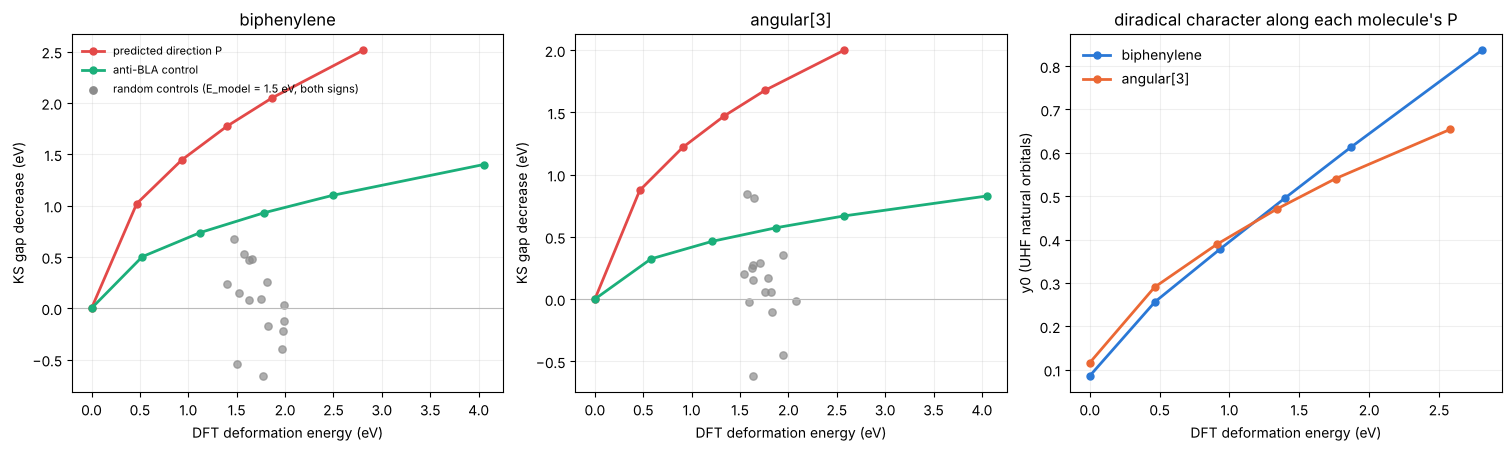

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), layout='constrained')
COL = {'P': '#e34948', 'BLA': '#1baf7a', 'R': '#8c8c8c'}
for ax, (nm, R) in zip(axes[:2], D.items()):
    for k, r in R.items():
        if k.startswith('R'):
            ax.scatter(r['dE'], r['dgap'], s=28, color=COL['R'], alpha=.7, zorder=2)
    for kind, lab in (('P', 'predicted direction P'), ('BLA', 'anti-BLA control')):
        L = ladder(R, kind)
        ax.plot([p['dE'] for p in L], [p['dgap'] for p in L], 'o-', color=COL[kind], lw=2, ms=5, label=lab, zorder=3)
    ax.scatter([], [], color=COL['R'], s=28, label='random controls (E_model = 1.5 eV, both signs)')
    ax.axhline(0, color='#bbbbbb', lw=.8)
    ax.set(title=nm, xlabel='DFT deformation energy (eV)', ylabel='KS gap decrease (eV)')
    ax.grid(alpha=.2)
axes[0].legend(frameon=False, fontsize=8, loc='upper left')
ax = axes[2]
for (nm, L), c in zip((('biphenylene', La), ('angular[3]', Lb)), ('#2a78d6', '#eb6834')):
    ax.plot([p['dE'] for p in L], [p['y0'] for p in L], 'o-', color=c, lw=2, ms=5, label=nm)
ax.set(title='diradical character along each molecule\'s P', xlabel='DFT deformation energy (eV)', ylabel='y0 (UHF natural orbitals)')
ax.legend(frameon=False); ax.grid(alpha=.2)
plt.show()

### 6.1 读法

**判据 1：通过，而且远高于门槛。** 模型挑出的方向，在 B3LYP 中每 eV 形变能压低的能隙，是同等模型代价随机方向中位数的 5–7 倍。随机方向中最好的一个也不到预测方向的一半；"把键长拉匀"的全对称对照只有预测方向的约 30–40%（联苯撑 0.52 对 1.27，角型 [3] 0.31 对 1.10）。粗糙的 Hückel + 弹簧模型找对了"往哪里推最有效"，而且这个方向在真实几何中可以精确实现。

**判据 2：不通过，两条子判据都失败。**

- 2a：形变能约 1.2 eV 以下，角型 [3] 的 y0 一直高于联苯撑，约 1.2 eV 处交叉，之后联苯撑反超。判据要求所有格点上联苯撑都更高。
- 2b：BS-UB3LYP 中 ⟨S²⟩ 首次超过 0.1，角型 [3] 在约 1.76 eV，联苯撑在约 1.87 eV。角型 [3] 先破缺，方向与预测相反。

**怎么理解。** 模型的反转说的是"能隙大的分子更便宜地关闭能隙"。B3LYP 中这件事在大形变区确实发生了：同等形变能下，两条能隙曲线在约 2.0 eV 处交叉（零形变时联苯撑高 0.34 eV，2.58 eV 时反而低 0.06 eV），y0 在约 1.2 eV 处交叉。但在决定"谁先变开壳层"的那一段，角型 [3] 本身更大的双自由基底子（参考点 y0 0.116 对 0.086，B3LYP 能隙 3.75 对 4.10 eV）盖过了方向效率的差别。也就是说，**机制在方向上成立，在排序上不足以翻盘。**

**本节结论的边界。** 只有一对分子；固定位移，不弛豫；y0 来自 UHF 自然轨道，会随分子尺寸系统性偏高，这对更大的角型 [3] 不利；第一次 UHF 收敛问题是在看到部分数据后修正的（见变更记录）。这些都不改变判据 1 的结论：它的余量是 3.6–4.4 倍的门槛距离，且只用 RKS 能量与能隙。


## 7. 收尾判断

按第 5 节事先定下的规则：**判据 1 通过、判据 2 不通过，只写机制，不写反转。** 不自动开启下一轮。

**能写的一句话：**

> 在含四元环的交替烃中，能隙对协同键长变化的响应集中在少数键上，其效率由前线轨道在键上的集中度决定；Hückel–弹簧模型据此给出的变形方向，在 B3LYP 中压低能隙的效率是随机同代价变形的 5–7 倍。

**不能写的：** "能隙更大的分子反而更容易被推向开壳层"。模型里成立，B3LYP 的这一对分子里不成立。

**稿子的骨架（小而完整）：**

1. ASC 相消给出的精确闭合条件与闭式（q² = 1/φ，q³ + q = 1），regularity radius 的精确算法：文献核对未见先例，作为支撑。
2. 机制：$\Delta E\approx g_0^2/(2a^TF^{-1}a)\approx(\kappa/8\alpha^2)\,g_0^2/P$，明确写成赝 Jahn–Teller / Heilbronner 框架的推论，以 Fowler & Rassat 2002 为直接先例。
3. 连接方式决定闭合是局域还是集体（角型 [3] 两个镜像局域见证）。
4. 一组事先登记的 DFT 检验：方向判据通过，排序判据不通过，如实报告。

**动笔前唯一必须补的：** 读 Fowler & Rassat 2002 全文。若其前线轨道规则已经等价于 P 并用于预测畸变代价，第 2 点只能写成"应用"，稿子的重心移到第 1、3、4 点。
